# Weighted KNN

## Overview

**Uniform KNN** treats the first and $k$-th neighbors equally — every neighbor gets the same vote.
**Weighted KNN** lets *closer* observations contribute more to the final prediction, giving stronger
influence to neighbors that are more similar to the query point.

For a query point $\mathbf{x}_q$, let $\mathcal{N}_k(\mathbf{x}_q)$ be the indices of the $k$ nearest
training points. Each neighbor $i \in \mathcal{N}_k(\mathbf{x}_q)$ is assigned a weight $w_i$
(e.g. $w_i = 1/d_i$ or a Gaussian function) that decays with distance.

> **Important:** Weighted KNN is almost always preferable to uniform KNN when distances are meaningful.
> A neighbor at distance 0.01 should influence the prediction far more than one at distance 10.0,
> yet uniform voting treats them identically.

---

## What is Weighted KNN?

Weighted k-NN assigns **higher importance to closer neighbors** and **lower importance to farther neighbors**
when making predictions. Instead of letting all $k$ nearest data points vote equally, it scales each
neighbor's contribution based on its **distance** from the query point.

### The Problem with Standard KNN

Two issues affect standard KNN:

1. **Choice of $k$:** Small $k$ → sensitive to outliers. Large $k$ → pulls in distant, irrelevant points.
2. **Majority voting:** The 10th neighbor (far away) gets the same vote as the 1st neighbor (very close),
   even though the closest neighbors more reliably indicate the true class.

### How Weighted KNN Resolves This

- **Outlier sensitivity:** A distant noisy point receives a very small weight ($w_i = 1/d_i^2 \to 0$
  for large $d_i$), so it has minimal influence.
- **Majority vote problem:** Each neighbor's contribution is proportional to its proximity.
  The closest neighbors — which most reliably reflect the query point's true class — dominate automatically.

### Algorithm Steps

1. **Calculate distances.** Measure the distance from the new query point to every training point.
2. **Select the $k$ nearest neighbors.** Sort distances and pick the top $k$ closest.
3. **Assign distance weights.** Compute $w_i$ for each neighbor:
   - Inverse distance: $w_i = \dfrac{1}{d_i}$
   - Inverse squared distance: $w_i = \dfrac{1}{d_i^2}$

   > **Note:** A tiny constant $\varepsilon$ is added ($w_i = 1/(d_i + \varepsilon)$) to prevent division by zero.

4. **Compute the final prediction.**
   - *Classification:* Sum the weights for each class → choose the highest.
   - *Regression:* Compute the weighted average of neighbor target values.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
import warnings
warnings.filterwarnings('ignore')

print('All imports loaded successfully.')

All imports loaded successfully.


## Uniform KNN vs Weighted KNN

| Aspect | Uniform KNN | Weighted KNN |
|--------|-------------|-------------|
| **Neighbor weights** | Equal — every neighbor gets vote = 1 | Distance-weighted — closer points get larger weights |
| **Sensitivity to $k$** | High — large $k$ pulls in distant points with equal weight | Lower — distant points receive minimal weight |
| **Imbalanced data** | Majority classes tend to dominate | Better — close minority-class point can outweigh farther majority |
| **Noise sensitivity** | Sensitive to any noisy point within $k$ radius | Robust against *distant* noise; still sensitive to noise right next to query |
| **Boundary shape** | Hard boundary | Smoother, more locally adaptive |
| **Variance** | Higher for small $k$ | Lower relative to uniform KNN |
| **Hyperparameters** | $k$ only | $k$ + weighting scheme + scheme parameters |
| **Best when** | All neighbors are equally relevant | Closer neighbors are more predictive |
| **sklearn** | `weights='uniform'` | `weights='distance'` or custom callable |

> **Note:** Neither is universally better. Compare both with cross-validation on your specific dataset.

## 1. Weighted Classification

### 1.1 Weighted Score and Prediction

For nonnegative weights $w_i(\mathbf{x}) \geq 0$, the **weighted vote score** for class $c$ is:

$$
\boxed{S_c(\mathbf{x}) = \sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i(\mathbf{x})\, \mathbb{1}(y_i = c)}
$$

The **predicted class** is the one with the highest weighted score:

$$
\boxed{\hat{y}(\mathbf{x}) = \arg\max_{c \in \mathcal{Y}}\ S_c(\mathbf{x})}
$$

**Where:**
- $\mathcal{N}_k(\mathbf{x})$ = set of $k$ nearest neighbors of query $\mathbf{x}$
- $w_i(\mathbf{x})$ = weight assigned to the $i$-th neighbor
- $\mathbb{1}(y_i = c)$ = indicator: 1 if neighbor $i$ belongs to class $c$, else 0
- $\mathcal{Y}$ = set of all possible class labels

### 1.2 Weighted Class Probabilities

**Weighted class probabilities** normalize the weighted scores so they sum to 1:

$$
\boxed{\hat{P}(Y = c \mid \mathbf{x}) = \frac{\displaystyle\sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i(\mathbf{x})\, \mathbb{1}(y_i = c)}{\displaystyle\sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i(\mathbf{x})}}
$$

This guarantees:
- $\hat{P}(Y = c \mid \mathbf{x}) \geq 0$ for all classes
- $\sum_c \hat{P}(Y = c \mid \mathbf{x}) = 1$ (valid probability distribution)

> **Note (sklearn):** `KNeighborsClassifier` handles probability normalization internally.
> When passing a custom `weights=` callable, return raw non-negative weights — sklearn normalizes them automatically.

## 2. Weighted Regression

For a **continuous target** $y_i \in \mathbb{R}$, weighted KNN regression returns the **weighted mean** of neighbor targets:

$$
\boxed{\hat{y}(\mathbf{x}) = \frac{\displaystyle\sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i(\mathbf{x})\, y_i}{\displaystyle\sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i(\mathbf{x})}}
$$

### Derivation via Weighted MSE

**Why this formula?** Minimize the weighted sum of squared errors inside the neighborhood:

$$L(a) = \sum_{i \in \mathcal{N}_k(\mathbf{x})} w_i (y_i - a)^2$$

Setting $\dfrac{dL}{da} = 0$:

$$-2\sum_i w_i y_i + 2a \sum_i w_i = 0 \quad \Longrightarrow \quad a = \frac{\sum_i w_i y_i}{\sum_i w_i}$$

> **Note:** Unweighted regression is a special case — when all $w_i = 1$, the formula reduces to the
> simple mean $\hat{y} = \frac{1}{k}\sum y_i$.

## 3. Weighting Schemes

### 3.1 Inverse-Distance Weights

The most common weighting rule — weight is inversely proportional to the distance raised to power $q$:

$$\boxed{w_i = \frac{1}{(d_i + \varepsilon)^q}, \qquad q > 0}$$

**Effect of $q$:**

| $q$ value | Behavior |
|-----------|----------|
| $q = 1$ | Linear inverse distance; moderate concentration |
| $q = 2$ | Quadratic inverse distance — very common default |
| $q \to 0$ | All weights approach equal (approaches uniform KNN) |
| $q \to \infty$ | Only the single closest neighbor matters |

> **Important:** Both $q$ and $\varepsilon$ affect predictions and should be treated as hyperparameters.
> Tune them with cross-validation.

---

### 3.2 Gaussian Weights and Nadaraya-Watson Connection

The **Gaussian kernel** assigns weight based on smooth exponential decay:

$$\boxed{w_i = \exp\left(-\frac{d_i^2}{2h^2}\right)}$$

**Properties:**
- **Never reaches zero** — all neighbors always have positive weight
- **Smooth decay** — no sharp cutoffs
- **No singularity at zero** — safe when exact matches exist

**Effect of $h$ (bandwidth):**

| $h$ value | Behavior |
|-----------|----------|
| Small $h$ | Sharp decay — distant neighbors weighted near zero |
| Large $h$ | Gentle decay — all neighbors contribute almost equally |
| $h \to \infty$ | All weights approach 1 (uniform KNN) |

#### Connection to Nadaraya-Watson Kernel Regression

When $k = n$ (all training points) with a Gaussian kernel, weighted KNN becomes the **Nadaraya-Watson** estimator:

$$\boxed{\hat{y}(\mathbf{x}) = \frac{\displaystyle\sum_{i=1}^{n} K_h(\mathbf{x} - \mathbf{x}_i)\, y_i}{\displaystyle\sum_{i=1}^{n} K_h(\mathbf{x} - \mathbf{x}_i)}}$$

where $K_h(t) = \exp\!\left(-\dfrac{\|t\|^2}{2h^2}\right)$ is the Gaussian kernel with bandwidth $h$.

---

### 3.3 Weight Normalization

After computing raw weights, normalize so they sum to 1:

$$\boxed{\tilde{w}_i = \frac{w_i}{\displaystyle\sum_{j \in \mathcal{N}_k(\mathbf{x})} w_j}}$$

**Why normalize?**
- Probability interpretation: normalized weights act as a probability distribution over neighbors
- The weighted mean formula already divides by $\sum w_i$, so normalization is implicit in regression
- Consistent scale: unnormalized weights change as distances change; normalized weights remain on $[0, 1]$

## 4. Handling Exact Matches (Zero Distance)

If one or more training observations have **distance zero** from the query, inverse-distance weights are
undefined (division by zero).

**Sensible policies:**

| Policy | Description | When to Use |
|--------|-------------|-------------|
| **Use only exact matches** | Ignore all non-zero-distance neighbors; aggregate only exact matches | Clean, labeled data without duplicates |
| **Add documented $\varepsilon$** | Use $w_i = 1/(d_i + \varepsilon)^q$; exact match weight is $1/\varepsilon^q$ | When some noise expected |
| **Detect contradictory duplicates** | Same features, different labels → resolve the data issue | Data quality problems |
| **Gaussian weights** | Never reach zero; no singularity issue | When smooth behavior at zero distance is preferred |

> **Caution:** If a neighbor has distance $d_i = 0$ and you use $w_i = 1/d_i^q$, its weight is
> mathematically infinite. A robust approach: *if any exact match exists, set its weight to 1 and
> all others to 0*, so the prediction is the label of the duplicate point.

## 5. Bias-Variance and Choosing K

As with standard KNN, the choice of $k$ trades off bias and variance:

| $k$ value | Bias | Variance | Risk |
|---|---|---|---|
| Small $k$ (e.g., $k=1$) | Low | **High** | Overfitting — predictions jump erratically |
| Large $k$ | **High** | Low | Underfitting — predicts global mean or majority class |

**How weighting interacts with $k$:**

- **Weighted KNN reduces variance** relative to uniform KNN at the same $k$, because closer points
  are emphasized over distant ones
- A small $k$ can still overfit with distance weighting by giving too much weight to very local noise
- Cross-validation is recommended to tune **both** $k$ and the weight function

> **Important:** Distance weighting reduces variance compared with uniform KNN, especially for
> moderate $k$. However, weighted KNN is **not strictly always better** — if the nearest neighbor
> is noisy or mislabeled, high weight amplifies the error.

## 6. When Weighting Helps or Hurts

### Weighting **Helps** When:

- **Proximity strongly predicts relevance** — closer neighbors are genuinely more similar
- The **nearest neighbor is much closer** than the $k$-th neighbor (large spread in distances)
- The **decision boundary is smooth** and local — weighting produces smoother boundaries
- **Regression targets vary smoothly** with feature distance

### Weighting **Hurts** When:

- The **closest neighbor is noisy or mislabeled** — high weight amplifies the error
- **Distances are not meaningful** (unscaled features, wrong metric)
- **Data is very sparse** — the nearest neighbor may still be far away, causing instability
- The **decision boundary is sharp** — weighting can blur it inappropriately

> **Warning:** Weighting can *increase* variance when the closest case is noisy — it effectively
> undoes the smoothing benefit of using larger $k$. A model with $k=7$ and distance weighting
> may behave similarly to $k=1$ uniform KNN if the closest neighbor dominates.

> **Tip:** Always compare uniform and distance weighting with cross-validation. There is no theoretical
> guarantee that one is better; the winner depends on your data's local density structure and noise level.

## 7. Numerical Examples

### 7.1 Classification Example

**Dataset:** Three neighbors for query point $\mathbf{x}_q$:

| Neighbor | Distance $d_i$ | Class $y_i$ |
|---|---|---|
| 1 | 1.0 | A |
| 2 | 2.0 | B |
| 3 | 5.0 | A |

**Scenario 1 — closest agrees with majority:**
- **Uniform KNN ($k=3$):** A=2 votes, B=1 → predict **A**
- **Weighted KNN ($q=1$):** $S_A = 1/1.0 + 1/5.0 = 1.200$, $S_B = 1/2.0 = 0.500$ → predict **A**

**Scenario 2 — closest *disagrees* with majority** (Neighbor 1 = B, Neighbors 2,3 = A):
- **Uniform KNN:** A=2, B=1 → predict **A**
- **Weighted ($q=1$):** $S_B = 1.000$, $S_A = 0.500 + 0.200 = 0.700$ → predict **B** ← *weighting reverses the vote!*

> **Note:** Distance-weighting can **reverse the majority decision** when the closest neighbor belongs
> to a minority class. Proximity is treated as stronger evidence than raw count.

In [6]:
# ── Classification Numerical Example ────────────────────────────────────────
import numpy as np
from collections import Counter

distances = np.array([1.0, 2.0, 5.0])

# ── Scenario 1: closest neighbor agrees with majority ─────────────────────
print('=' * 55)
print('Scenario 1: Closest neighbor AGREES with majority')
print('=' * 55)
classes1 = np.array(['A', 'B', 'A'])

vote1 = Counter(classes1)
print(f'Uniform vote counts: {dict(vote1)}')
print(f'Uniform prediction:  {vote1.most_common(1)[0][0]}')

weights1 = 1.0 / distances
S_A1 = weights1[classes1 == 'A'].sum()
S_B1 = weights1[classes1 == 'B'].sum()
print(f'\nWeighted (q=1): S_A = {S_A1:.3f}, S_B = {S_B1:.3f}')
print(f'Weighted prediction: {"A" if S_A1 > S_B1 else "B"}')

# ── Scenario 2: closest neighbor DISAGREES with majority ──────────────────
print('\n' + '=' * 55)
print('Scenario 2: Closest neighbor DISAGREES with majority')
print('=' * 55)
classes2 = np.array(['B', 'A', 'A'])  # Neighbor 1 is now B

vote2 = Counter(classes2)
print(f'Uniform vote counts: {dict(vote2)}')
print(f'Uniform prediction:  {vote2.most_common(1)[0][0]}')

weights2 = 1.0 / distances
S_A2 = weights2[classes2 == 'A'].sum()
S_B2 = weights2[classes2 == 'B'].sum()
print(f'\nWeighted (q=1): S_A = {S_A2:.3f}, S_B = {S_B2:.3f}')
print(f'Weighted prediction: {"A" if S_A2 > S_B2 else "B"}')
print('\n→ Weighting REVERSED the majority vote because the closest')
print('  neighbor (d=1.0) belonged to class B.')

Scenario 1: Closest neighbor AGREES with majority
Uniform vote counts: {np.str_('A'): 2, np.str_('B'): 1}
Uniform prediction:  A

Weighted (q=1): S_A = 1.200, S_B = 0.500
Weighted prediction: A

Scenario 2: Closest neighbor DISAGREES with majority
Uniform vote counts: {np.str_('B'): 1, np.str_('A'): 2}
Uniform prediction:  A

Weighted (q=1): S_A = 0.700, S_B = 1.000
Weighted prediction: B

→ Weighting REVERSED the majority vote because the closest
  neighbor (d=1.0) belonged to class B.


### 7.2 Regression Example

**Dataset:** Training points along a line:

| $x_i$ | $y_i$ |
|---|---|
| 0 | 0 |
| 1 | 1 |
| 2 | 4 |
| 3 | 9 |

**Query point:** $x_q = 1.5$, $k = 3$ neighbors.

**Step 1 — Distances from $x_q = 1.5$:**
- $(0, 0)$: $d = 1.5$
- $(1, 1)$: $d = 0.5$
- $(2, 4)$: $d = 0.5$
- $(3, 9)$: $d = 1.5$ ← **excluded** (4th nearest, tie)

Three nearest neighbors: $(1, 1)$, $(2, 4)$, $(0, 0)$ with $y = 1, 4, 0$.

**Step 2 — Uniform KNN:**
$$\hat{y}_{\text{uniform}} = \frac{1 + 4 + 0}{3} = 1.67$$

**Step 3 — Weighted KNN ($q=1$):**
- $w_{(0,0)} = 1/1.5 = 0.667$, $\quad w_{(1,1)} = 1/0.5 = 2.000$, $\quad w_{(2,4)} = 1/0.5 = 2.000$
$$\hat{y} = \frac{0 \times 0.667 + 1 \times 2.000 + 4 \times 2.000}{0.667 + 2.000 + 2.000} = \frac{10.000}{4.667} \approx 2.14$$

**Step 4 — Weighted KNN ($q=2$):**
- $w_{(0,0)} = 1/1.5^2 = 0.444$, $\quad w_{(1,1)} = 1/0.5^2 = 4.000$, $\quad w_{(2,4)} = 4.000$
$$\hat{y} = \frac{0 \times 0.444 + 1 \times 4.000 + 4 \times 4.000}{0.444 + 4.000 + 4.000} = \frac{20.000}{8.444} \approx 2.37$$

**Summary:**

| Method | Prediction |
|---|---|
| Uniform ($w_i = 1$) | 1.67 |
| Inverse-distance $q=1$ | 2.14 |
| Inverse-distance $q=2$ | 2.37 |

In [7]:
# ── Regression Numerical Example — Step-by-Step Verification ────────────────
import numpy as np

x_train = np.array([0.0, 1.0, 2.0, 3.0])
y_train = np.array([0.0, 1.0, 4.0, 9.0])
xq = 1.5

# Step 1 — Distances
distances = np.abs(x_train - xq)
print('Distances from xq=1.5:')
for xi, yi, di in zip(x_train, y_train, distances):
    print(f'  (x={xi:.0f}, y={yi:.0f})  d = {di:.1f}')

# Step 2 — Select k=3 nearest (note: ties at d=1.5; numpy picks first by index)
k = 3
sort_idx = np.argsort(distances)[:k]
d3 = distances[sort_idx]
y3 = y_train[sort_idx]
print(f'\n3 nearest: x={x_train[sort_idx]}, y={y3}, d={d3}')

# Step 3 — Uniform KNN
y_uniform = y3.mean()
print(f'\nUniform KNN:         ŷ = {y_uniform:.4f}')

# Step 4 — Weighted q=1
w1 = 1.0 / d3
y_w1 = np.dot(w1, y3) / w1.sum()
print(f'Weighted KNN (q=1):  ŷ = {y_w1:.4f}')

# Step 5 — Weighted q=2
w2 = 1.0 / d3**2
y_w2 = np.dot(w2, y3) / w2.sum()
print(f'Weighted KNN (q=2):  ŷ = {y_w2:.4f}')

print('\n── Summary ──────────────────────────────────')
print(f'  Uniform (w_i=1)   |  {y_uniform:.2f}')
print(f'  Inverse-dist q=1  |  {y_w1:.2f}')
print(f'  Inverse-dist q=2  |  {y_w2:.2f}')
print('\nAs q increases, closer points (d=0.5) get even more emphasis.')
print('The far neighbor (d=1.5, y=0) is down-weighted → prediction shifts up.')

Distances from xq=1.5:
  (x=0, y=0)  d = 1.5
  (x=1, y=1)  d = 0.5
  (x=2, y=4)  d = 0.5
  (x=3, y=9)  d = 1.5

3 nearest: x=[1. 2. 0.], y=[1. 4. 0.], d=[0.5 0.5 1.5]

Uniform KNN:         ŷ = 1.6667
Weighted KNN (q=1):  ŷ = 2.1429
Weighted KNN (q=2):  ŷ = 2.3684

── Summary ──────────────────────────────────
  Uniform (w_i=1)   |  1.67
  Inverse-dist q=1  |  2.14
  Inverse-dist q=2  |  2.37

As q increases, closer points (d=0.5) get even more emphasis.
The far neighbor (d=1.5, y=0) is down-weighted → prediction shifts up.


## 8. Python Implementation

### 8.1 From-Scratch Implementation

The two functions below implement weighted KNN without sklearn.
Key design choices:

- **Exact match guard:** If any training point is at distance $< \varepsilon$ from the query,
  return that point's label directly — no inverse-distance computation on a near-zero denominator.
- **Inverse-distance weights:** $w_i = 1/(d_i + \varepsilon)^q$ where $\varepsilon = 10^{-8}$ prevents
  division by zero in ordinary cases.
- **Classification:** Sums weights per class, returns the highest-weight class.
- **Regression:** Returns the weighted mean of neighbor targets.

In [8]:
import numpy as np

def weighted_knn_classify(X_train, y_train, x_query, k=3, q=1, eps=1e-8):
    """Weighted KNN classification from scratch."""
    dists = np.linalg.norm(X_train - x_query, axis=1)
    nn_idx = np.argsort(dists)[:k]

    # Exact match: return the first exact match's label immediately
    zero_mask = dists[nn_idx] < eps
    if np.any(zero_mask):
        return y_train[nn_idx[zero_mask][0]]

    weights = 1.0 / (dists[nn_idx] + eps) ** q
    classes = np.unique(y_train[nn_idx])
    weight_sums = {c: weights[y_train[nn_idx] == c].sum() for c in classes}
    return max(weight_sums, key=weight_sums.get)


def weighted_knn_regress(X_train, y_train, x_query, k=3, q=2, eps=1e-8):
    """Weighted KNN regression from scratch."""
    dists = np.linalg.norm(X_train - x_query, axis=1)
    nn_idx = np.argsort(dists)[:k]

    zero_mask = dists[nn_idx] < eps
    if np.any(zero_mask):
        return y_train[nn_idx[zero_mask][0]]

    weights = 1.0 / (dists[nn_idx] + eps) ** q
    return np.dot(weights, y_train[nn_idx]) / weights.sum()


# ── Classification demo ────────────────────────────────────────────────────
X_cls = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_cls = np.array(['A', 'A', 'B', 'B'])
xq_cls = np.array([0.9, 0.2])

print('── From-Scratch Classification ──────────────────────────')
print('Training: (0,0)→A  (0,1)→A  (1,0)→B  (1,1)→B')
print(f'Query: {xq_cls}')
for q_val in [1, 2]:
    pred = weighted_knn_classify(X_cls, y_cls, xq_cls, k=3, q=q_val)
    print(f'  Predicted class (q={q_val}): {pred}')

# ── Regression demo ────────────────────────────────────────────────────────
X_reg  = np.array([[0.0], [1.0], [2.0], [3.0]])
y_reg  = np.array([0.0, 1.0, 4.0, 9.0])
xq_reg = np.array([1.5])

print('\n── From-Scratch Regression ───────────────────────────────')
print('Training: x=[0,1,2,3], y=[0,1,4,9]   Query: xq=1.5, k=3')
print(f'  Uniform mean:       {y_reg[np.argsort(np.abs(X_reg.ravel()-1.5))[:3]].mean():.4f}')
print(f'  Weighted (q=1):     {weighted_knn_regress(X_reg, y_reg, xq_reg, k=3, q=1):.4f}')
print(f'  Weighted (q=2):     {weighted_knn_regress(X_reg, y_reg, xq_reg, k=3, q=2):.4f}')

── From-Scratch Classification ──────────────────────────
Training: (0,0)→A  (0,1)→A  (1,0)→B  (1,1)→B
Query: [0.9 0.2]
  Predicted class (q=1): B
  Predicted class (q=2): B

── From-Scratch Regression ───────────────────────────────
Training: x=[0,1,2,3], y=[0,1,4,9]   Query: xq=1.5, k=3
  Uniform mean:       1.6667
  Weighted (q=1):     2.1429
  Weighted (q=2):     2.3684


### 8.2 Scikit-Learn with Pipeline and GridSearchCV

Best practice for Weighted KNN in sklearn:

1. **Wrap in a `Pipeline(StandardScaler, KNN)`** — scaling happens inside CV folds, preventing data leakage.
2. **Use `GridSearchCV`** to jointly tune `n_neighbors` and `weights`.

> **Data leakage risk:** Fitting the scaler on the full dataset *before* CV inflates performance estimates.
> Putting the scaler inside the Pipeline ensures it is fit only on training folds.

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
import warnings
warnings.filterwarnings('ignore')

# ── 1. Load and split ──────────────────────────────────────────────────────
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

# ── 2. Pipeline: StandardScaler → KNN ─────────────────────────────────────
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',    KNeighborsClassifier())
])

# ── 3. GridSearchCV over k and weight options ──────────────────────────────
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9],
    'knn__weights':     ['uniform', 'distance']
}
gs = GridSearchCV(pipeline, param_grid, cv=5)
gs.fit(X_train, y_train)

print('Best params:  ', gs.best_params_)
print('CV accuracy:  ', round(gs.best_score_, 4))
print('Test accuracy:', round(gs.score(X_test, y_test), 4))

# ── 4. Quick uniform vs distance comparison (with scaling pipeline) ─────────
print('\n── Uniform vs Distance Weighting (5-fold CV) ──')
for w in ['uniform', 'distance']:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn',    KNeighborsClassifier(n_neighbors=5, weights=w))
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    print(f"  weights='{w}': {scores.mean():.4f} ± {scores.std():.4f}")


Best params:   {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
CV accuracy:   0.9557
Test accuracy: 1.0

── Uniform vs Distance Weighting (5-fold CV) ──
  weights='uniform': 0.9289 ± 0.0534
  weights='distance': 0.9466 ± 0.0333


### Custom Weight Functions

sklearn's `weights=` parameter accepts any callable with signature `f(distances) -> weights`.
This allows Gaussian kernels, power-law decay, or any other scheme.

> **Tip:** When passing a custom callable, return raw non-negative weights — sklearn normalizes
> them internally when computing class probabilities. The callable receives an array of shape
> `(n_queries, k)` and must return an array of the same shape.

Custom inv-distance (q=2):  test acc = 0.9737
Gaussian kernel (h=1.0):    test acc = 0.9737
q=2 decays much faster than q=1; Gaussian has a smooth bell-shaped decay.


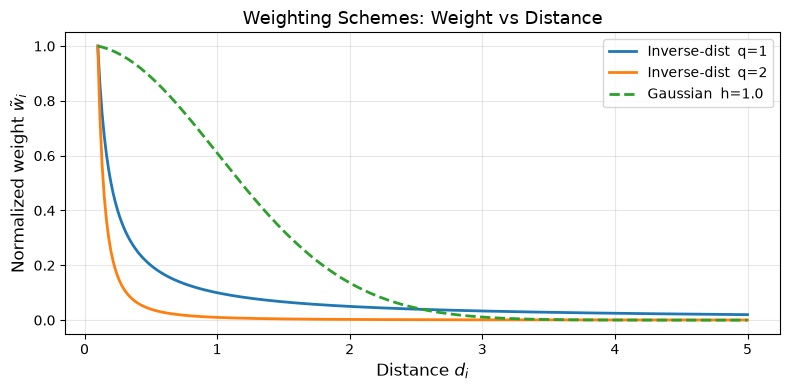

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# ── Custom weight callables ────────────────────────────────────────────────
def inv_distance_q(distances, q=2, eps=1e-8):
    """Inverse-distance weight with configurable power q."""
    return 1.0 / (distances + eps) ** q

def gaussian_weights(distances, h=1.0):
    """Gaussian kernel weights with bandwidth h."""
    return np.exp(-(distances ** 2) / (2 * h ** 2))

# Apply to Iris dataset with scaling pipeline
clf_inv = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',    KNeighborsClassifier(n_neighbors=5, weights=inv_distance_q))
])
clf_gauss = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',    KNeighborsClassifier(n_neighbors=5, weights=gaussian_weights))
])

clf_inv.fit(X_train, y_train)
clf_gauss.fit(X_train, y_train)

print(f'Custom inv-distance (q=2):  test acc = {clf_inv.score(X_test, y_test):.4f}')
print(f'Gaussian kernel (h=1.0):    test acc = {clf_gauss.score(X_test, y_test):.4f}')

# ── Visualize weight decay curves ─────────────────────────────────────────
# Start d_range from 0.1 to avoid the 1/0 singularity at d=0
d_range = np.linspace(0.1, 5, 300)
w_inv1  = 1.0 / d_range
w_inv2  = 1.0 / (d_range ** 2)
w_gauss = np.exp(-d_range**2 / (2 * 1.0**2))

# Normalize each so weight at closest plotted distance (d=0.1) equals 1.0
w_inv1_n  = w_inv1  / w_inv1[0]
w_inv2_n  = w_inv2  / w_inv2[0]
w_gauss_n = w_gauss / w_gauss[0]

plt.figure(figsize=(8, 4))
plt.plot(d_range, w_inv1_n, label='Inverse-dist  q=1', lw=2)
plt.plot(d_range, w_inv2_n, label='Inverse-dist  q=2', lw=2)
plt.plot(d_range, w_gauss_n, label='Gaussian  h=1.0',   lw=2, linestyle='--')
plt.xlabel('Distance $d_i$', fontsize=12)
plt.ylabel('Normalized weight $\\tilde{w}_i$', fontsize=12)
plt.title('Weighting Schemes: Weight vs Distance', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print('q=2 decays much faster than q=1; Gaussian has a smooth bell-shaped decay.')


## 9. Key Points and Applications

### Advantages of Weighted KNN

- **Reduces variance** compared to uniform KNN, especially for moderate $k$
- Can **break ties** that uniform voting cannot
- **Smoother, more locally adaptive** decision boundaries
- Still **lazy learning** (zero training cost) — no parametric fitting required
- Works with **any distance-compatible feature type** (numeric, binary, mixed)

### Limitations

- Shares KNN's **curse of dimensionality** — distance becomes less discriminative in high dimensions
- **Slow at query time** for large datasets unless accelerated with KD-trees, Ball trees, or FAISS
- **More sensitive to outliers** in the nearest neighborhood than uniform KNN
- **Feature scaling is essential** — without it, large-scale features dominate the distance

### Hyperparameters to Tune

| Hyperparameter | Options | How to Tune |
|---|---|---|
| $k$ | 1–20+ | Cross-validation |
| Weight function | `'uniform'`, `'distance'`, Gaussian, custom | Cross-validation |
| Distance metric | Euclidean, Manhattan, Minkowski, Cosine | Domain knowledge + CV |
| Power $q$ (inverse-distance) | 1, 2, or grid | Cross-validation |
| Bandwidth $h$ (Gaussian) | Real-valued | Cross-validation |

### Use Cases

- **Spatial interpolation** — geographic prediction where proximity is physically meaningful
- **Recommender systems** — users/items nearby in embedding space are most relevant
- **Medical diagnosis** — local similarity to known cases matters
- **Simple regression baseline** — often competitive with basic parametric models on small datasets

---

### Summary

| | Uniform KNN | Weighted KNN |
|---|---|---|
| **Prediction formula** | Majority vote / simple mean | Weighted vote / weighted mean |
| **Weight per neighbor** | $w_i = 1$ | $w_i = 1/d_i^q$ or Gaussian |
| **Variance** | Higher | Lower for moderate $k$ |
| **Noise sensitivity** | Moderate | Lower (distant noise) / Higher (close noise) |
| **sklearn parameter** | `weights='uniform'` | `weights='distance'` |
| **Tune with** | $k$ only | $k$, scheme, $q$ or $h$ |

---

<p align="center">
  ⬅️ <strong>Previous:</strong> <a href="./08%20Weighted%20KNN.md">08 Weighted KNN</a> &nbsp;&nbsp;|&nbsp;&nbsp; <strong>Next:</strong> <a href="./09%20Curse%20of%20Dimensionality%20and%20Special%20Data%20Types.md">09 Curse of Dimensionality and Special Data Types</a> ➡️
</p>